# Batch Cell Cycle & Morphology Analysis

This notebook loads exported `pheno.results` snapshots (`properties.csv`, `metadata.csv`, `img_path.json`) across dataset splits (`train`, `test`, `test_drugged`, etc.) and provides reusable clustering, visual inspection, and cross-split comparison workflows.

## 1. Setup & Exported Results Loader

Loads all exported runs/splits from `analysis_exports/` (CSV + JSON), guarantees `time_min` exists to avoid `KeyError` crashes, and keeps `img_path` aligned row-for-row with each cell's properties and metadata.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile as tiff
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

export_root = Path("analysis_exports")
records = []

if export_root.exists():
    for run_dir in sorted(export_root.iterdir()):
        if not run_dir.is_dir():
            continue

        props_file = run_dir / "properties.csv"
        meta_file = run_dir / "metadata.csv"
        img_file = run_dir / "img_path.json"

        if not props_file.exists():
            continue

        props_df = pd.read_csv(props_file)
        meta_df = pd.read_csv(meta_file) if meta_file.exists() else pd.DataFrame(index=range(len(props_df)))

        if "time_min" not in meta_df.columns:
            meta_df["time_min"] = meta_df["frame"] if "frame" in meta_df.columns else 0

        overlap = set(props_df.columns) & set(meta_df.columns)
        meta_clean = meta_df.add_prefix("meta_") if overlap else meta_df

        run_df = pd.concat([props_df, meta_clean], axis=1)
        run_df["split"] = run_dir.name
        run_df["sample_idx"] = np.arange(len(run_df))

        if img_file.exists():
            with open(img_file, "r") as f:
                paths = json.load(f)
            if len(paths) == len(run_df):
                run_df["img_path"] = paths

        records.append(run_df)

assert records, f"No exported runs found in '{export_root.resolve()}'. Export at least one split first."
all_df = pd.concat(records, ignore_index=True)

def find_col(df: pd.DataFrame, candidates: list[str]) -> str | None:
    lower_map = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    return None

ch0_col = find_col(all_df, ["Intensity_mean_masked_ch0", "intensity_mean_masked_ch0"])
ch1_col = find_col(all_df, ["Intensity_mean_masked_ch1", "intensity_mean_masked_ch1"])
area_col = find_col(all_df, ["Area", "area"])
sol_col = find_col(all_df, ["Solidity", "solidity"])
time_col = find_col(all_df, ["time_min", "frame"])

print("Splits loaded:", all_df["split"].value_counts().to_dict())
print("Detected columns:", {"ch0": ch0_col, "ch1": ch1_col, "area": area_col, "solidity": sol_col, "time": time_col})

Splits loaded: {'test_drugged_tracksall_stride1': 51, 'test_tracksall_stride1': 30}
Detected columns: {'ch0': 'intensity_mean_masked_ch0', 'ch1': 'intensity_mean_masked_ch1', 'area': 'area', 'solidity': 'solidity', 'time': 'time_min'}


## 2. Reusable clustering & Visual inspection helpers

Wraps K-Means clustering, `(ch0, ch1)` scatter overview, and sample image grids into reusable functions so you can test different splits, feature sets, and cluster counts without duplicating code.

In [2]:
def run_cluster_analysis(
    df: pd.DataFrame,
    feature_cols: list[str],
    n_clusters: int = 4,
    label_col: str = "cluster",
    random_state: int = 42,
):
    valid_cols = [c for c in feature_cols if c is not None]
    assert len(valid_cols) >= 1, f"No valid feature columns found in {feature_cols}"

    out = df.dropna(subset=valid_cols).copy()
    X_scaled = StandardScaler().fit_transform(out[valid_cols].to_numpy(dtype=float))
    model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
    out[label_col] = model.fit_predict(X_scaled)
    return out, valid_cols


def load_cell_image(raw_path):
    if not raw_path or pd.isna(raw_path):
        return None
    p = Path(str(raw_path))
    if not p.exists() and p.suffix.lower() == ".npy":
        for tag in ("train", "test", "test_drugged"):
            alt = Path(
                str(p)
                .replace(f"/{tag}/images/", f"/{tag}/{tag}_tiff/")
                .replace(f"\\{tag}\\images\\", f"\\{tag}\\{tag}_tiff\\")
            ).with_suffix(".tiff")
            if alt.exists():
                p = alt
                break
    if not p.exists():
        return None

    arr = np.load(p) if p.suffix.lower() == ".npy" else tiff.imread(p)
    arr = np.squeeze(arr)
    if arr.ndim == 3 and arr.shape[0] <= 4 and arr.shape[0] < arr.shape[1] and arr.shape[0] < arr.shape[2]:
        arr = np.moveaxis(arr, 0, -1)

    arr = arr.astype(np.float32)
    vmin, vmax = np.nanmin(arr), np.nanmax(arr)
    arr = (arr - vmin) / (vmax - vmin) if vmax > vmin else np.zeros_like(arr)

    if arr.ndim == 3 and arr.shape[-1] == 2:
        rgb = np.zeros((*arr.shape[:2], 3), dtype=np.float32)
        rgb[..., 0] = arr[..., 0]
        rgb[..., 1] = arr[..., 1]
        return rgb
    return arr[..., :3] if (arr.ndim == 3 and arr.shape[-1] > 3) else arr


def plot_cluster_overview(
    df: pd.DataFrame,
    label_col: str,
    ch0: str,
    ch1: str,
    area: str | None = None,
    sol: str | None = None,
    title: str = "",
):
    summary_cols = [c for c in [ch0, ch1, area, sol] if c is not None]
    print(f"\n--- Summary for '{label_col}' ({title}) ---")
    display(df.groupby(label_col)[summary_cols].agg(["count", "mean"]))

    fig, ax = plt.subplots(figsize=(6.5, 5))
    for cid, grp in df.groupby(label_col):
        ax.scatter(grp[ch0], grp[ch1], label=f"{label_col}={cid} (n={len(grp)})", alpha=0.8, s=30)
    ax.set_xlabel(ch0)
    ax.set_ylabel(ch1)
    ax.set_title(title or f"({ch0}, {ch1}) by {label_col}")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_cluster_crops(
    df: pd.DataFrame,
    label_col: str,
    area: str | None = None,
    sol: str | None = None,
    n_samples: int = 4,
):
    clusters = sorted(df[label_col].unique())
    fig, axes = plt.subplots(len(clusters), n_samples, figsize=(3.3 * n_samples, 3.6 * len(clusters)))
    if len(clusters) == 1:
        axes = np.expand_dims(axes, axis=0)

    for r_idx, cid in enumerate(clusters):
        grp = df[df[label_col] == cid].head(n_samples)
        for c_idx in range(n_samples):
            ax = axes[r_idx, c_idx]
            ax.axis("off")
            if c_idx < len(grp):
                row = grp.iloc[c_idx]
                img = load_cell_image(row.get("img_path"))
                if img is not None:
                    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
                else:
                    ax.text(0.5, 0.5, f"idx={row['sample_idx']}\n(no img)", ha="center", va="center", fontsize=8)

                parts = [f"C{cid} | #{row['sample_idx']}"]
                if area and pd.notna(row.get(area)):
                    parts.append(f"A={row[area]:.0f}")
                if sol and pd.notna(row.get(sol)):
                    parts.append(f"S={row[sol]:.2f}")
                ax.set_title(" ".join(parts), fontsize=8)

    plt.tight_layout()
    plt.show()

## 3. Baseline Analysis : intensity + morphology on selected split

Clusters cells on `ch0`, `ch1`, `area`, and `solidity` for a chosen split (defaulting to `"test"` if available) and displays sample crops per cluster.

**Basic properties :**
- Count : Number of cells assigned to that cluster
- Intensity_mean_masked_ch0 & intensity_mean_masked_ch1 : Mean fluorescence intensity of Channel 0 and Channel 1 inside the segmented cell/nuclear mask.
- Area : Cell/nuclear area (in pixels), reflecting cell size/growth.
- Solidity : Ratio of object area to its convex hull area (1.0 = smooth, convex, compact shape; lower values = more irregular, indented, or elongated/dividing contours).

Exception in thread Thread-4 (_readerthread):
Traceback (most recent call last):
  File "c:\Users\jufki\miniforge3\envs\phenome-cpu\Lib\threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "c:\Users\jufki\miniforge3\envs\phenome-cpu\Lib\threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\jufki\miniforge3\envs\phenome-cpu\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "<frozen codecs>", line 322, in decode
UnicodeDecodeError: 'utf-8' codec can't decode byte 0x82 in position 110: invalid start byte



--- Summary for 'morph_phase_cluster' (test_drugged_tracksall_stride1 — Intensity + Morphology (k=4)) ---


intensity_mean_masked_ch0            \
                                        count      mean   
morph_phase_cluster                                       
0                                          34  0.548515   
1                                           4  0.344819   
2                                           8  0.624970   
3                                           5  0.460772   

                    intensity_mean_masked_ch1            area              \
                                        count      mean count        mean   
morph_phase_cluster                                                         
0                                          34  0.784392    34  635.147059   
1                                           4  0.596673     4  364.250000   
2                                           8  0.808900     8  859.375000   
3                                           5  0.615501     5  834.000000   

                    solidity            
                       count      mean  
morph_phase_cluster                     
0                         34  0.968125  
1                          4  0.954940  
2                          8  0.894402  
3                          5  0.972247

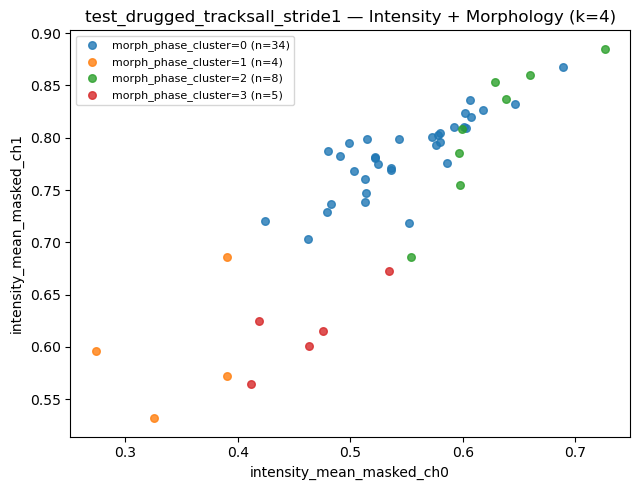

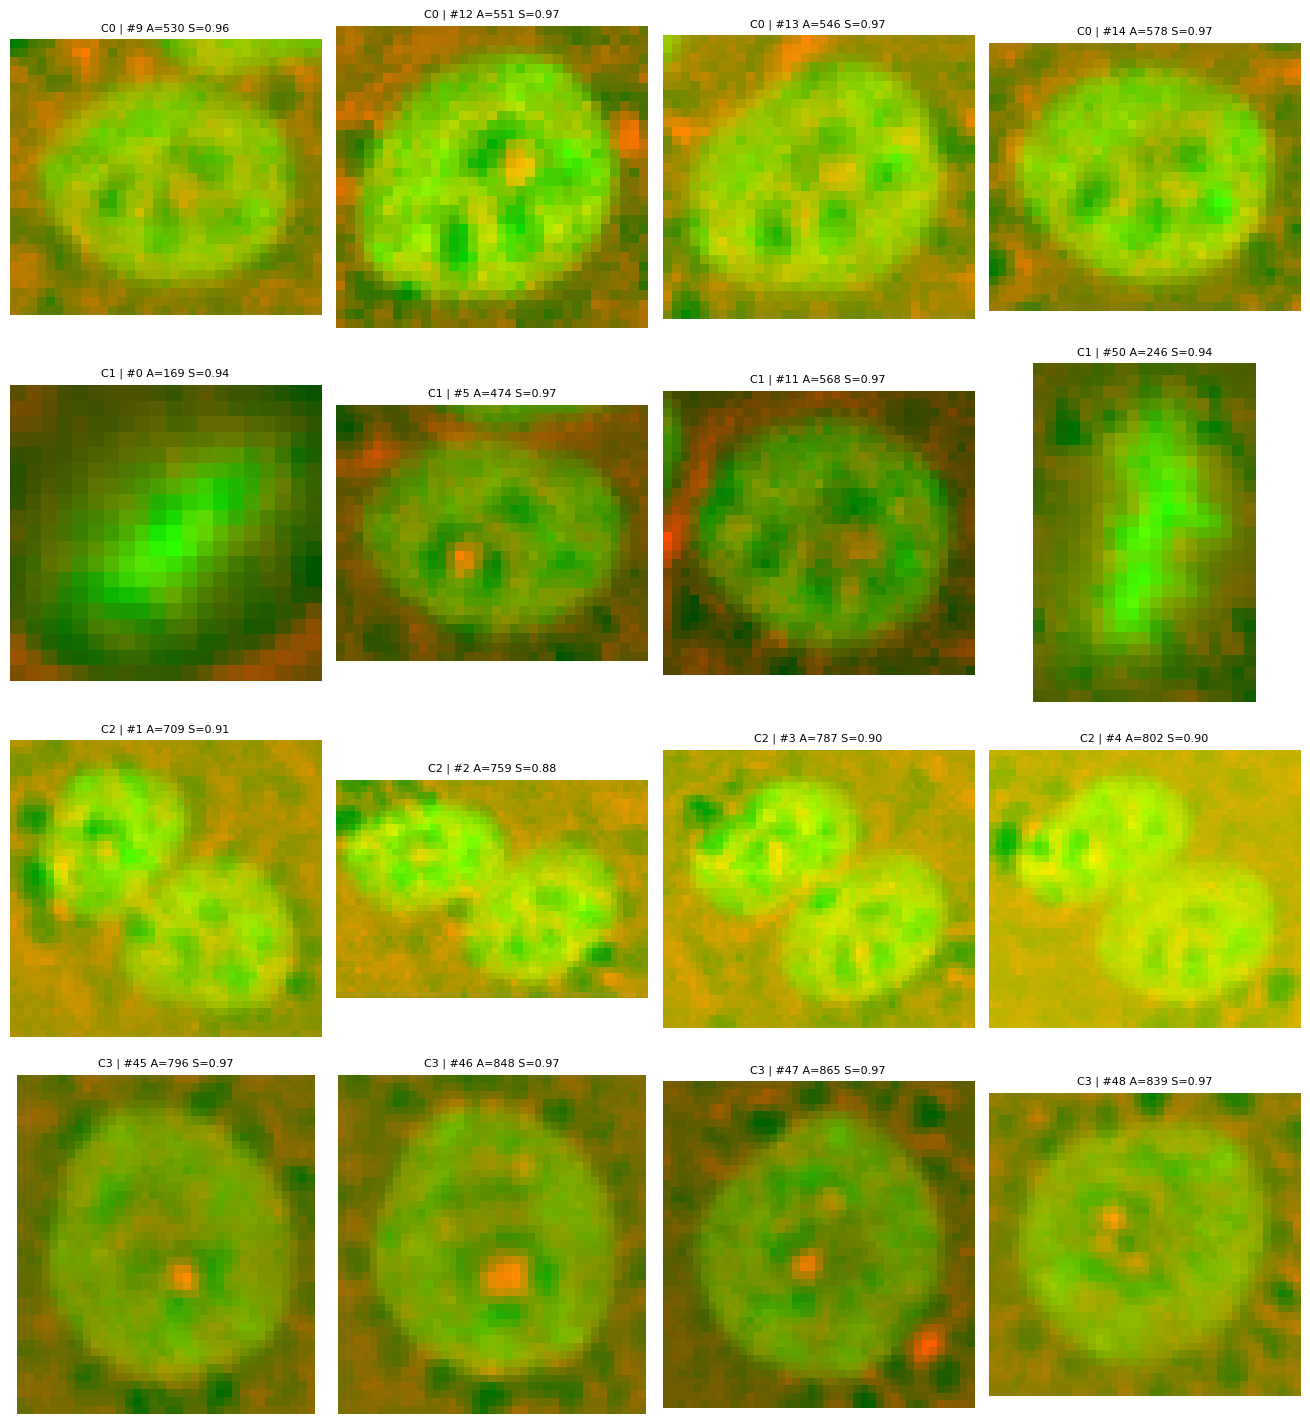

In [3]:
target_split = "test" if "test" in all_df["split"].unique() else all_df["split"].iloc[0]
split_df = all_df[all_df["split"] == target_split].copy()

morph_clustered_df, _ = run_cluster_analysis(
    split_df,
    feature_cols=[ch0_col, ch1_col, area_col, sol_col],
    n_clusters=4,
    label_col="morph_phase_cluster",
)

plot_cluster_overview(
    morph_clustered_df,
    label_col="morph_phase_cluster",
    ch0=ch0_col,
    ch1=ch1_col,
    area=area_col,
    sol=sol_col,
    title=f"{target_split} — Intensity + Morphology (k=4)",
)
plot_cluster_crops(morph_clustered_df, label_col="morph_phase_cluster", area=area_col, sol=sol_col, n_samples=4)

**Interpretation of the clusters :**

Cluster 0 (n = 34, majority population)
- Moderate-to-high signal in both channels (ch0 = 0.55, ch1 = 0.78), medium area (= 635), and high solidity (= 0.97).
- This is your main baseline/intermediate-to-high intensity group with smooth, regular shapes. Because it contains 34 of the 51 cells, it represents the most common ongoing state/phase in this subset (for example, a standard interphase state such as S/G2 or an intermediate FUCCI profile).

Cluster 1 (n = 4, very small group)
- Lowest intensity in both channels (ch0 = 0.34, ch1 = 0.60), smallest area (= 364), and high solidity (= 0.95)
- Small, compact cells with comparatively dim fluorescence in both channels. In a cell-cycle context, these could correspond to small newly divided/early-stage cells.

Cluster 2 (n = 8, high-intensity & largest/least compact group)
- Highest intensity in both channels (ch0 = 0.62, ch1 = 0.81), largest area (= 859), and lowest solidity (= 0.89).
- Large cells/regions with strong signal in both channels and slightly less convex/more irregular shapes. 
- Lower solidity alongside larger area is a classic signature to check for mitotic/dividing cells.

Cluster 3 (n = 5, small group with large area but lower channel intensity)
- Lower intensity in both channels (ch0 = 0.46, ch1 = 0.62) compared to Cluster 0 and Cluster 2, large area (≈ 834), and very high solidity (≈ 0.97).
- Large, smooth/compact objects whose fluorescence intensity is noticeably lower than Cluster 2 despite having nearly the same large area. This suggests either a distinct biological state/phase where reporter intensity hasn't peaked (or is diluted over a large area) or a specific morphological sub-population worth checking visually.

## 4. Example A : intensity-only clustering (ignoring cell size & solidity)

Groups cells strictly by fluorescence intensity (`ch0` and `ch1`) so cell-cycle intensity progression isn't split by large single nuclei or multi-nucleus/dividing shapes.


--- Summary for 'intensity_cluster' (test_drugged_tracksall_stride1 — Intensity Only (k=4)) ---


intensity_mean_masked_ch0            \
                                      count      mean   
intensity_cluster                                       
0                                        20  0.507912   
1                                         6  0.664614   
2                                        17  0.590429   
3                                         8  0.393646   

                  intensity_mean_masked_ch1            area              \
                                      count      mean count        mean   
intensity_cluster                                                         
0                                        20  0.751037    20  648.100000   
1                                         6  0.856023     6  798.000000   
2                                        17  0.803295    17  679.941176   
3                                         8  0.598980     8  598.500000   

                  solidity            
                     count      mean  
intensity_cluster                     
0                       20  0.963113  
1                        6  0.913244  
2                       17  0.959005  
3                        8  0.963459

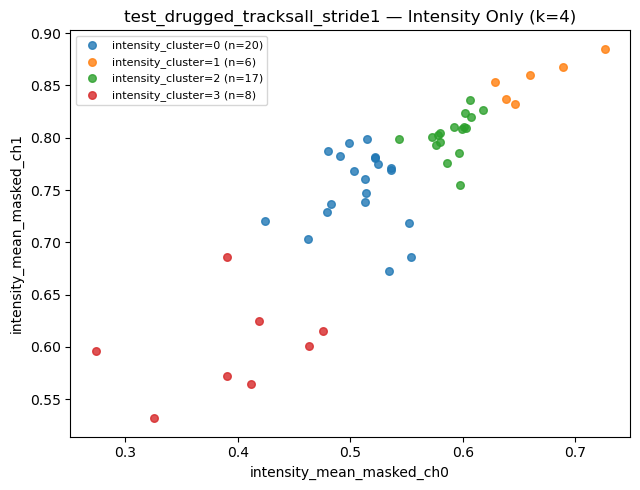

In [4]:
int_clustered_df, _ = run_cluster_analysis(
    split_df,
    feature_cols=[ch0_col, ch1_col],
    n_clusters=4,
    label_col="intensity_cluster",
)

plot_cluster_overview(
    int_clustered_df,
    label_col="intensity_cluster",
    ch0=ch0_col,
    ch1=ch1_col,
    area=area_col,
    sol=sol_col,
    title=f"{target_split} — Intensity Only (k=4)",
)

## 5. Example B : cross-split comparison (`train` vs. `test` vs. `test_drugged`)

Fits one shared scaler and `KMeans` model across **all** loaded splits so cluster IDs mean the same thing everywhere, then compares cluster distributions and progression over `time_min` across conditions.


Cluster share (%) within each split:


shared_intensity_cluster,0,1,2,3
split,,,,
test_drugged_tracksall_stride1,23.5,15.7,17.6,43.1
test_tracksall_stride1,33.3,16.7,26.7,23.3



Mean time_min by split and cluster:


count         mean
split                          shared_intensity_cluster                    
test_drugged_tracksall_stride1 0                            12  1175.000000
                               1                             8  1581.250000
                               2                             9  1244.444444
                               3                            22  1172.727273
test_tracksall_stride1         0                            10   640.000000
                               1                             5   780.000000
                               2                             8   612.500000
                               3                             7   935.714286

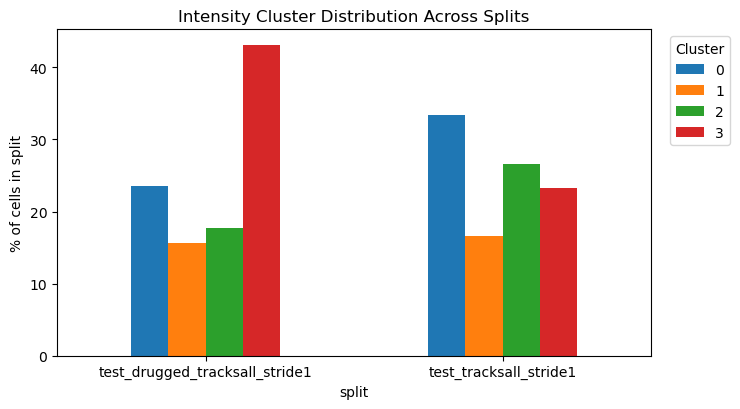

In [5]:
shared_df, used_feats = run_cluster_analysis(
    all_df,
    feature_cols=[ch0_col, ch1_col],
    n_clusters=4,
    label_col="shared_intensity_cluster",
)

prop_table = pd.crosstab(shared_df["split"], shared_df["shared_intensity_cluster"], normalize="index") * 100
print("\nCluster share (%) within each split:")
display(prop_table.round(1))

if time_col is not None:
    print(f"\nMean {time_col} by split and cluster:")
    display(shared_df.groupby(["split", "shared_intensity_cluster"])[time_col].agg(["count", "mean"]))

prop_table.plot(kind="bar", figsize=(7.5, 4.2))
plt.ylabel("% of cells in split")
plt.title("Intensity Cluster Distribution Across Splits")
plt.xticks(rotation=0)
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 6. Example C: Single Timepoint / Frame Snapshot (`time_min` or `frame`)

Isolates a single timepoint (defaulting to the earliest recorded timepoint) to examine population heterogeneity at a fixed moment in time.

Snapshot at time_min == 0 (n=1):


snapshot_cluster
0    1
Name: count, dtype: int64


--- Summary for 'snapshot_cluster' (test_drugged_tracksall_stride1 @ time_min=0) ---


intensity_mean_masked_ch0            \
                                     count      mean   
snapshot_cluster                                       
0                                        1  0.273841   

                 intensity_mean_masked_ch1            area        solidity  \
                                     count      mean count   mean    count   
snapshot_cluster                                                             
0                                        1  0.596431     1  169.0        1   

                            
                      mean  
snapshot_cluster            
0                 0.944134

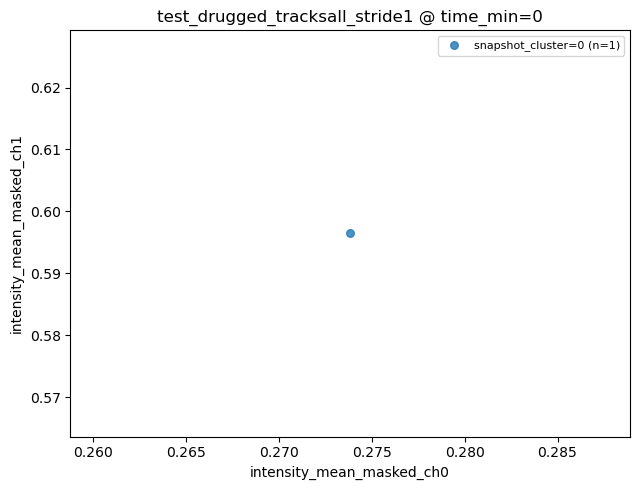

In [7]:
if time_col is not None:
    first_t = split_df[time_col].min()
    snap_df = split_df[split_df[time_col] == first_t].copy()
    n_k = min(3, len(snap_df)) if len(snap_df) >= 2 else 1
    snap_clustered, _ = run_cluster_analysis(
        snap_df,
        feature_cols=[ch0_col, ch1_col, area_col, sol_col],
        n_clusters=n_k,
        label_col="snapshot_cluster",
    )
    print(f"Snapshot at {time_col} == {first_t} (n={len(snap_clustered)}):")
    display(snap_clustered["snapshot_cluster"].value_counts())
    plot_cluster_overview(
        snap_clustered,
        label_col="snapshot_cluster",
        ch0=ch0_col,
        ch1=ch1_col,
        area=area_col,
        sol=sol_col,
        title=f"{target_split} @ {time_col}={first_t}",
    )